# Partially coherent holography with a GitHub-logo

We use a circular phase pupil to form a Gaussian-smoothed GitHub logo on a monitor at $z_2=1\,\mathrm m$. The illumination is an extended, spatially incoherent source. Its angular width and the pupil diameter set how much detail we can reproduce.

The source and pupil amplitude stay fixed. We optimize only the phase, using Eq. (24) to calculate the irradiance and JAX to differentiate it. 

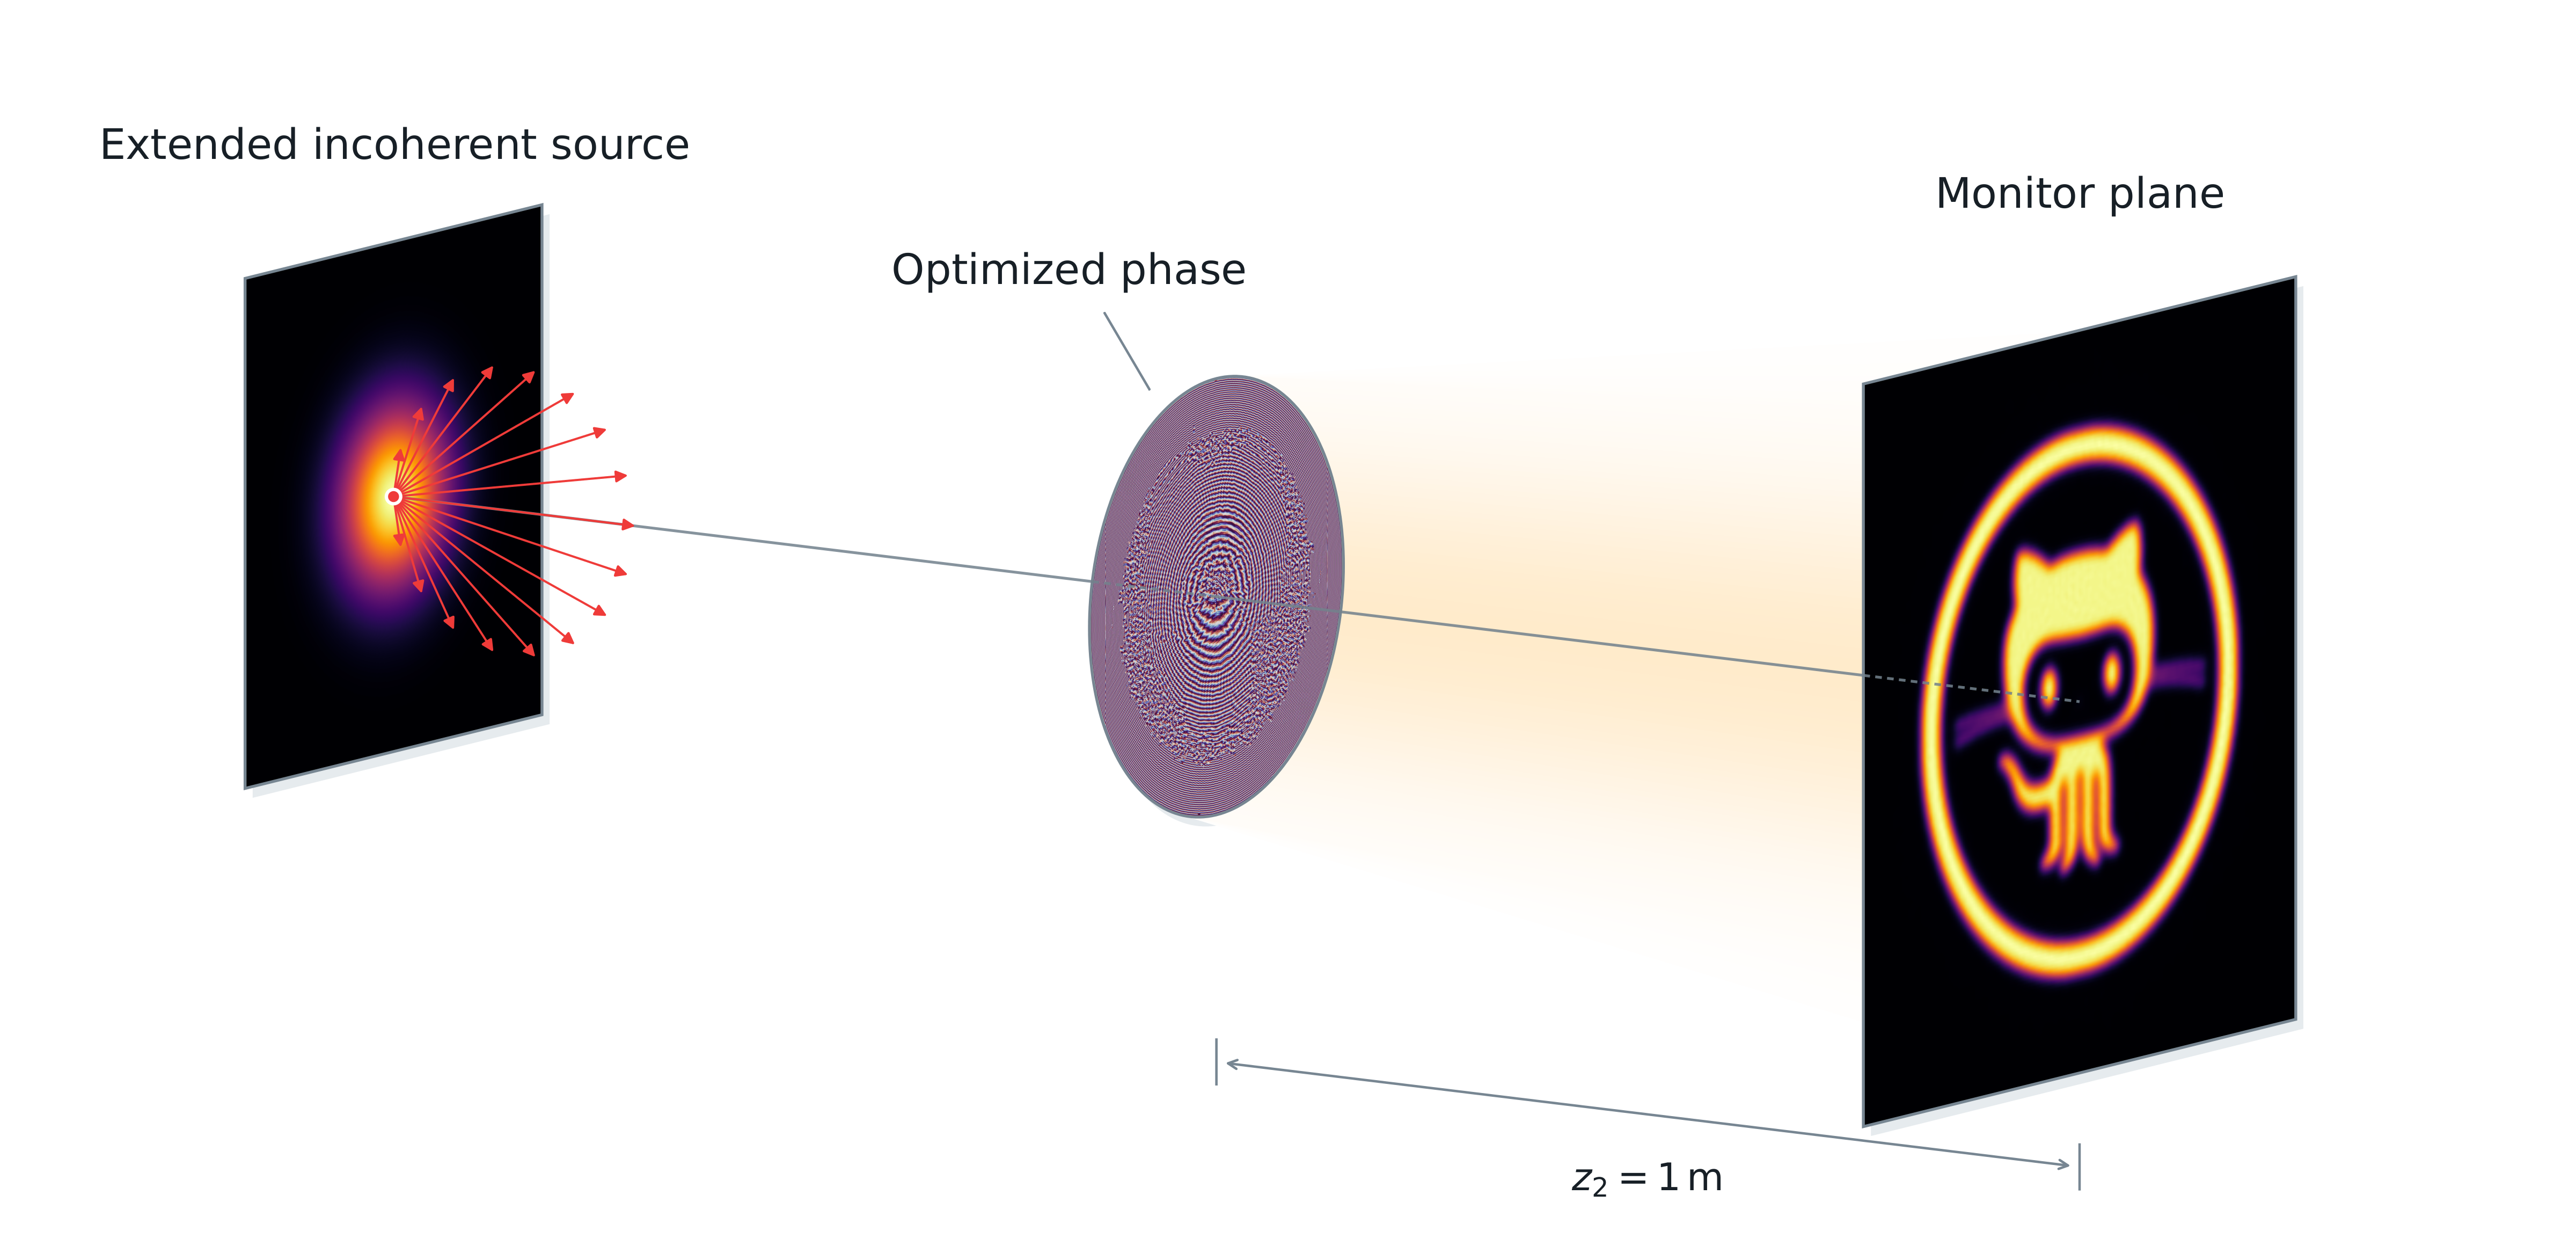

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
from jax.example_libraries import optimizers

import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import IncoherentLightSimulation, ApertureFromFunction, m, mm, um, nm
from diffractsim import load_image_as_function
from diffractsim.util.backend_functions import backend as bd

plt.rcParams["figure.dpi"] = 140

## 1. Define the extended source

Each source direction contributes independently. We describe the angular radiance by

$$
L_{\mathrm{in}}(\alpha',\beta')=
\frac{E_{\mathrm{in}}}{2\pi\sigma^2}
\exp\!\left[-\frac{(\alpha')^2+(\beta')^2}{2\sigma^2}\right],
$$

with $E_{\mathrm{in}}=1\,\mathrm{W\,m^{-2}}$. The finite source width smooths the pattern. We choose it smaller than the target's Gaussian smoothing width, so the face and gaps between the legs remain visible.

The wavelength is $940\,\mathrm{nm}$. The pupil grid has $1024\times1024$ samples, spaced by $2\,\mu\mathrm m$.

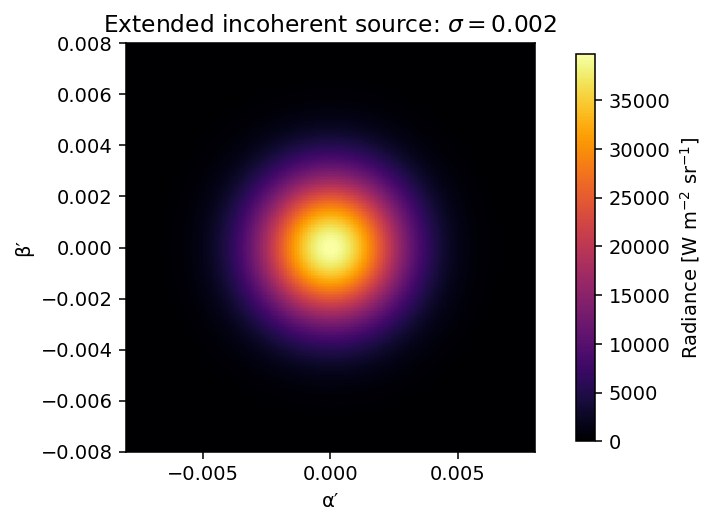

In [2]:
# 1. Define and plot the Gaussian angular source.
wavelength, N, pixel = 940*nm, 1024, 2*um
extent, z2 = N*pixel, 1*m
sigma, incident_irradiance = 0.002, 1.0
source_limit = 6*sigma
sim = IncoherentLightSimulation(wavelength, extent, extent, N, N)

def angular_source(alpha, beta):
    """Gaussian radiance, truncated at six standard deviations."""
    L = incident_irradiance*bd.exp(-(alpha**2+beta**2)/(2*sigma**2))/(2*bd.pi*sigma**2)
    return bd.where((abs(alpha) <= source_limit) & (abs(beta) <= source_limit), L, 0)

sim.set_angular_illumination(angular_source, paraxial=False,
    angular_samples=8192,
    source_bounds=(-source_limit, source_limit, -source_limit, source_limit))

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
sim.plot_source_radiance(xlim=(-4*sigma, 4*sigma), ylim=(-4*sigma, 4*sigma),
    ax=ax, title=rf"Extended incoherent source: $\sigma={sigma:g}$")
plt.show()

## 2. Choose the circular pupil and starting phase

The pupil transmission is

$$
\mathscr P(\xi,\eta)=A(\xi,\eta)e^{i\phi(\xi,\eta)},
\qquad
A(\xi,\eta)=
\begin{cases}1,&\xi^2+\eta^2\le R^2,\\0,&\text{otherwise}.\end{cases}
$$

The diameter is about $1.88\,\mathrm{mm}$. This larger aperture provides enough resolution for the smoothed logo. We start with a diverging quadratic phase that spreads light toward the target, plus a small, reproducible perturbation. Every illuminated phase pixel is free to change.

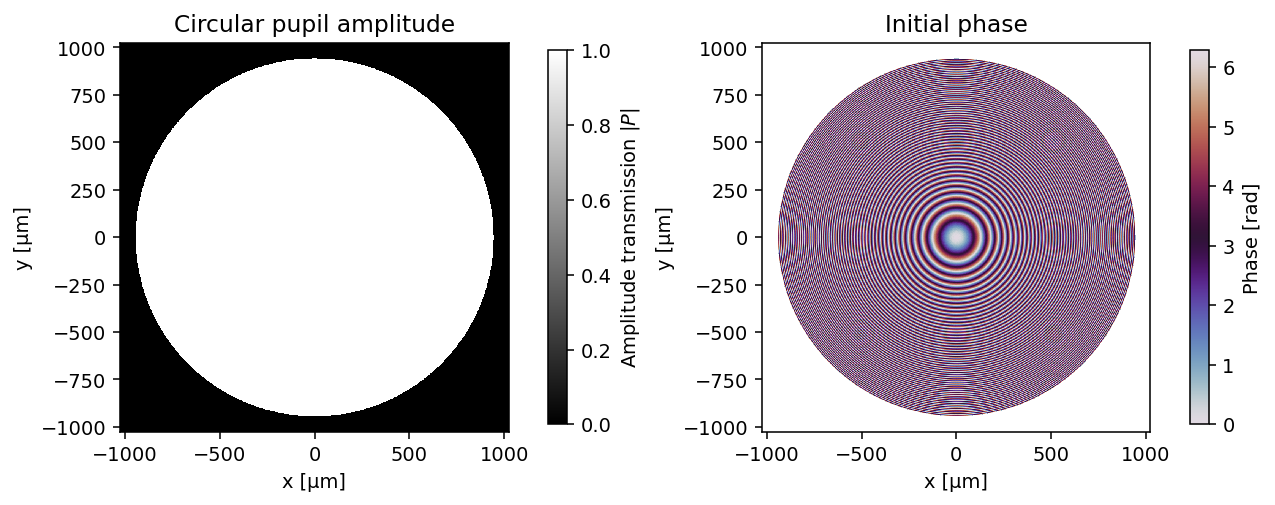

In [3]:
# 2. Define and plot the circular pupil and initial phase.
radius, spread = 0.46*extent, 0.11
amplitude = (sim.xx**2+sim.yy**2 <= radius**2).astype(float)

rng = np.random.default_rng(2)
phi_initial = bd.pi/wavelength*(spread/radius)*(sim.xx**2+sim.yy**2)
phi_initial += 0.04*bd.asarray(rng.normal(size=(N, N)))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), layout="constrained")
sim.plot_aperture(amplitude, units=um, ax=axes[0], title="Circular pupil amplitude")
sim.plot_aperture(amplitude*bd.exp(1j*phi_initial), phase=True, units=um,
    ax=axes[1], title="Initial phase")
plt.show()

## 3. Turn the image into a smooth irradiance target

We apply a Gaussian filter to the image before optimization. Here the logo is $220\,\mathrm{mm}$ wide and the filter has a standard deviation of $2.5\,\mathrm{mm}$. `load_image_as_function` places the image in these physical coordinates and applies the filter once. It keeps the logo upright and adds black padding so the outer ring can blur beyond the image boundary.

If $g=G_{\sigma_T}*I_{\mathrm{logo}}$ is the smoothed grayscale image, the target is

$$
T(x,y)=\frac{P_0\,g(x,y)}{\displaystyle\iint_{\mathcal A}g\,\mathrm dA},
\qquad
P_0=E_{\mathrm{in}}\iint A^2\,\mathrm d\xi\,\mathrm d\eta.
$$

This fixes the target's absolute brightness using the transmitted power. The monitor spans $300\times300\,\mathrm{mm}$ and includes $y=0$. The optical model defines this monitor through `zoom_propagate`; the simulator returns its irradiance as a two-dimensional image.

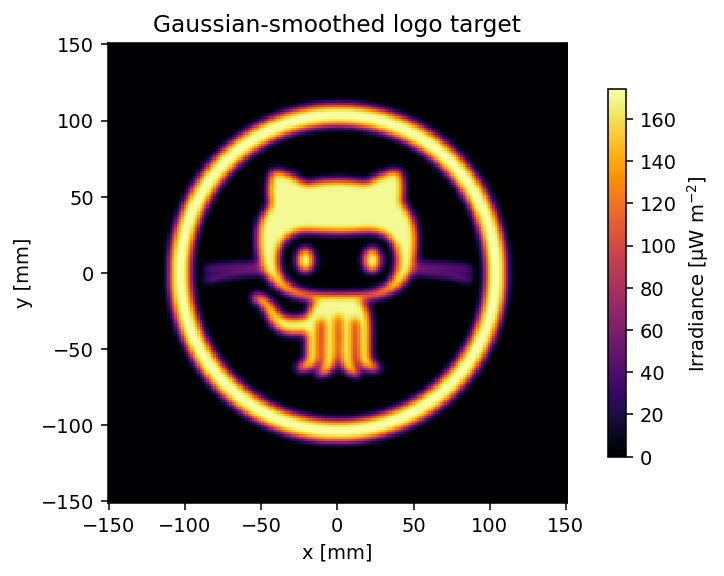

In [4]:
# 3. Load, smooth and normalize the logo at z2.
logo_width, smoothing = 220*mm, 2.5*mm
monitor_x = monitor_y = np.linspace(-150*mm, 150*mm, 201)
screen_x, screen_y = np.meshgrid(monitor_x, monitor_y)
pixel_area = (monitor_x[1]-monitor_x[0])*(monitor_y[1]-monitor_y[0])

logo = load_image_as_function("github_logo.png", x_interval=(-logo_width/2, logo_width/2), y_interval=(-logo_width/2, logo_width/2), smoothing=smoothing)
target_shape = logo(screen_x, screen_y)

power_target = sim.get_incident_irradiance()*bd.sum(amplitude**2)*pixel**2
target = power_target*target_shape/(target_shape.sum()*pixel_area)
irradiance_units = 1e-6  # Display irradiance in µW/m².

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
sim.plot_map(monitor_x, monitor_y, target/irradiance_units, units=mm, ax=ax,
    labels=("x [mm]", "y [mm]"), colorbar_label=r"Irradiance [µW m$^{-2}$]",
    title="Gaussian-smoothed logo target", cmap="inferno", vmin=0)
plt.show()

## 4. Optimize the phase

For each trial phase, `forward` applies the circular pupil and calculates the monitor irradiance $E_\phi$ with Eq. (24). We retain `model="Fresnel", sampling="angular"`: the pupil response uses the angular Fresnel approximation, including the direction-cosine mapping and monitor weighting.

We minimize the image error and penalize power missing from the monitor:

$$
\mathcal L(\phi)=
\frac{\displaystyle\iint_{\mathcal A}(E_\phi-T)^2\,\mathrm dA}
     {\displaystyle\iint_{\mathcal A}T^2\,\mathrm dA}
+5\left(1-\frac{\displaystyle\iint_{\mathcal A}E_\phi\,\mathrm dA}{P_0}\right)^2.
$$

Both terms use absolute irradiance; the simulated image is not rescaled to fit the target. JAX differentiates the complete calculation, and Adam updates the phase for 2,000 steps.

   0: loss = 0.517794
 200: loss = 0.002078
 400: loss = 0.001312
 600: loss = 0.001044
 800: loss = 0.000907
1000: loss = 0.000823
1200: loss = 0.000765
1400: loss = 0.000721
1600: loss = 0.000686
1800: loss = 0.000656


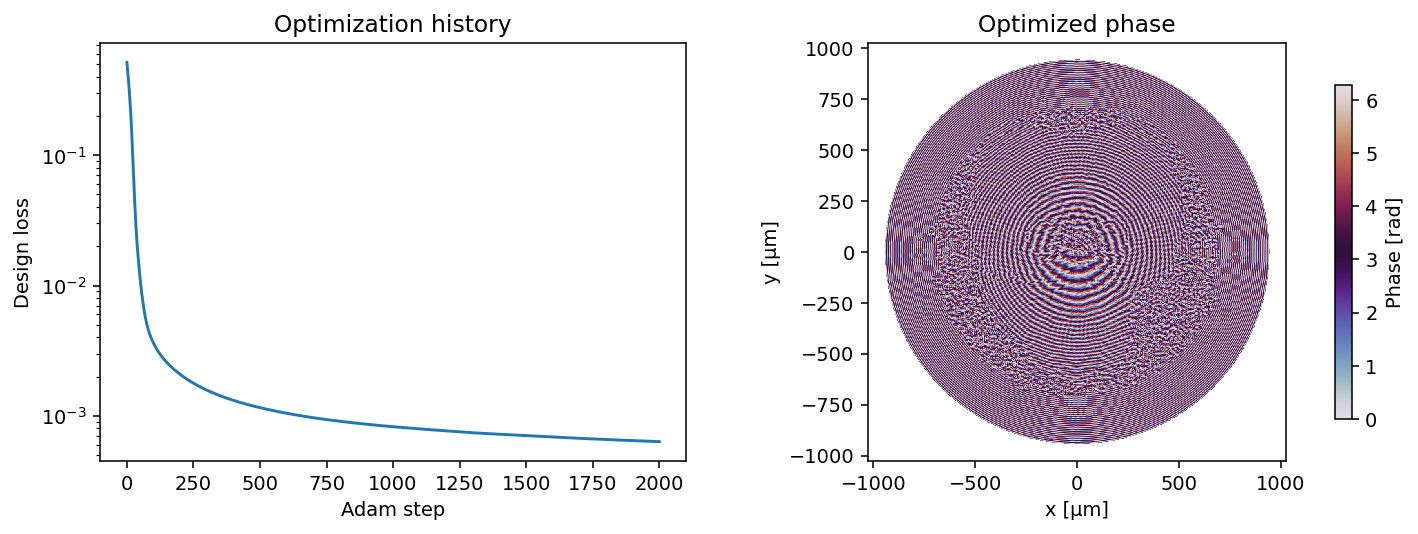

In [5]:
# 4. Define the optical model and loss, then optimize the phase.
iterations, learning_rate = 2000, 0.08

def forward(phi):
    """Return the irradiance on the monitor for this pupil phase."""
    plate = ApertureFromFunction(lambda x, y, wl: amplitude*bd.exp(1j*phi))

    def optical_setup(F, z):
        return F.add(plate).zoom_propagate(z,
            x_interval=[monitor_x[0], monitor_x[-1]],
            y_interval=[monitor_y[0], monitor_y[-1]],
            Nx_mon=len(monitor_x), Ny_mon=len(monitor_y),
            model="Fresnel", sampling="angular")

    return sim.get_irradiance(optical_setup, z2)[2]

def objective(phi):
    E = forward(phi)
    image_error = bd.sum((E-target)**2)/bd.sum(target**2)
    power_error = (1-bd.sum(E)*pixel_area/power_target)**2
    return image_error+5*power_error

opt_init, opt_update, get_params = optimizers.adam(step_size=learning_rate)

@jax.jit
def step(i, state):
    loss, gradient = jax.value_and_grad(objective)(get_params(state))
    return opt_update(i, gradient, state), loss

state, history = opt_init(phi_initial), []
for i in range(iterations):
    state, loss = step(i, state)
    history.append(float(loss))
    if i % 200 == 0:
        print(f"{i:4d}: loss = {float(loss):.6f}")

phi_optimized = get_params(state)
history.append(float(objective(phi_optimized)))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
axes[0].semilogy(history)
axes[0].set(xlabel="Adam step", ylabel="Design loss", title="Optimization history")
sim.plot_aperture(amplitude*bd.exp(1j*phi_optimized), phase=True, units=um,
    ax=axes[1], title="Optimized phase")
plt.show()

## 5. Compare the reconstructed logo with the target

We evaluate the optimized phase with the same optical model. The two images share one color scale, and the horizontal cut at $y=0$ compares their absolute irradiance. We report the relative image error $\|E_\phi-T\|_2/\|T\|_2$ and the fraction of transmitted power that reaches the monitor.

Relative image error: 2.18% | Power on monitor: 99.44%


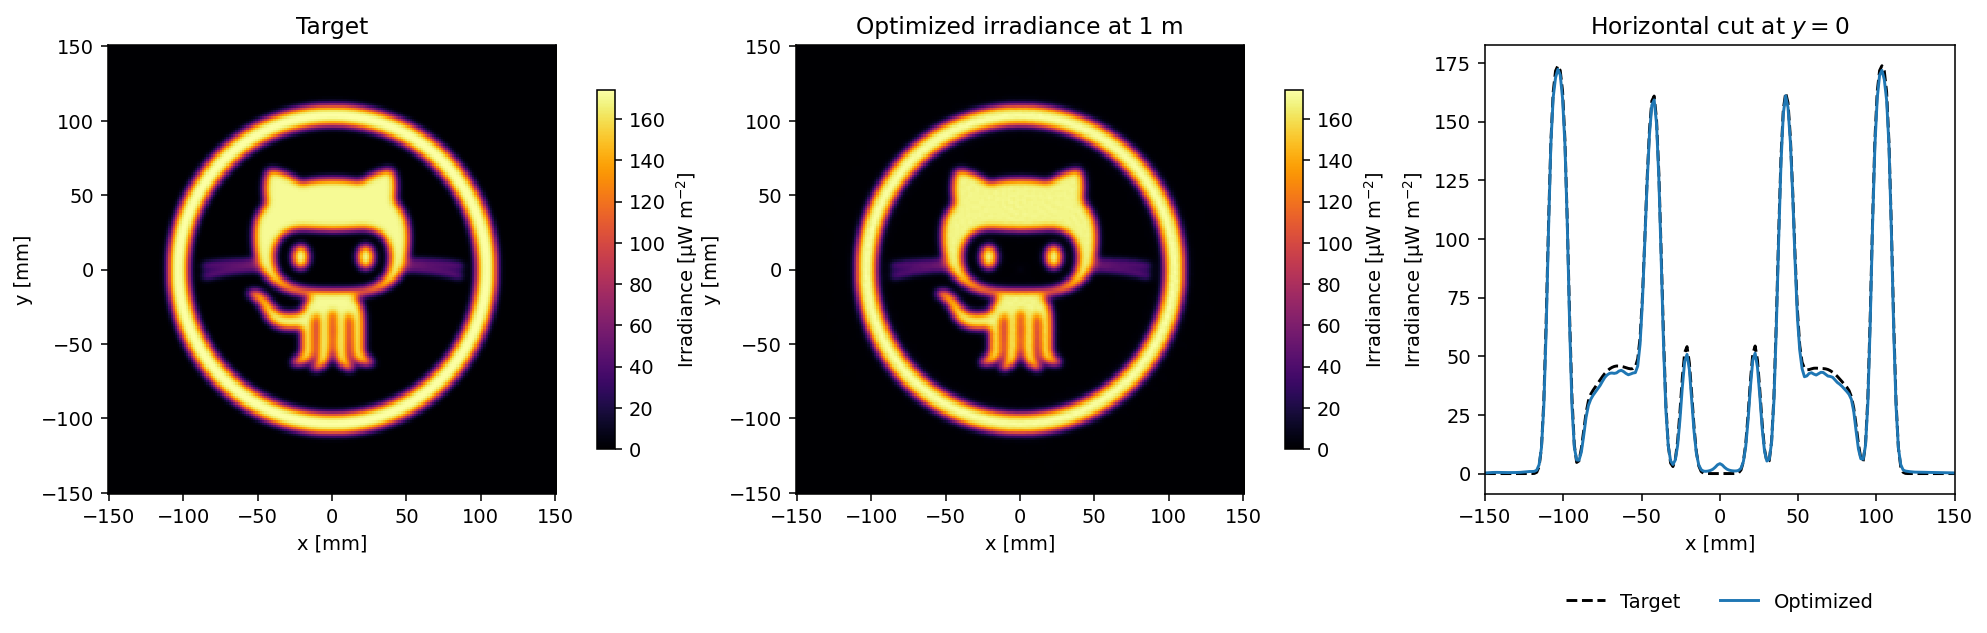

In [6]:
# 5. Simulate the optimized pupil and inspect the reconstruction.
optimized_E = forward(phi_optimized)
relative_error = bd.sqrt(bd.sum((optimized_E-target)**2)/bd.sum(target**2))
collection = bd.sum(optimized_E)*pixel_area/power_target
print(f"Relative image error: {100*float(relative_error):.2f}% | "
      f"Power on monitor: {100*float(collection):.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
vmax = float(bd.max(target))/irradiance_units
for ax, values, title in zip(axes[:2], [target, optimized_E], ["Target", "Optimized irradiance at 1 m"]):
    sim.plot_map(monitor_x, monitor_y, values/irradiance_units, units=mm, ax=ax,
        labels=("x [mm]", "y [mm]"), colorbar_label=r"Irradiance [µW m$^{-2}$]",
        title=title, cmap="inferno", vmin=0, vmax=vmax)

row = len(monitor_y)//2
axes[2].plot(monitor_x/mm, np.asarray(target[row]/irradiance_units), "k--", label="Target")
axes[2].plot(monitor_x/mm, np.asarray(optimized_E[row]/irradiance_units), label="Optimized")
axes[2].set(xlabel="x [mm]", ylabel=r"Irradiance [µW m$^{-2}$]",
    title=r"Horizontal cut at $y=0$", xlim=(monitor_x[0]/mm, monitor_x[-1]/mm))
axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.show()

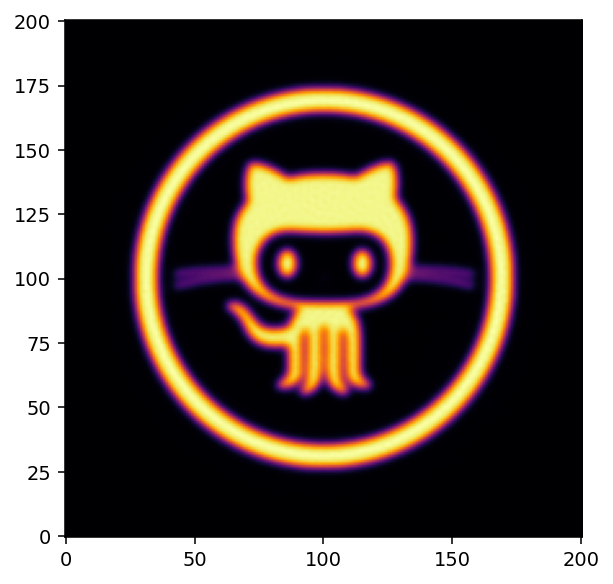

In [7]:
wavelength, N, pixel = 940*nm, 1024, 2*um
extent, z2 = N*pixel, 1*m
sigma, incident_irradiance = 0.002, 1.0
source_limit = 6*sigma
sim = IncoherentLightSimulation(wavelength, extent, extent, N, N)

def angular_source(alpha, beta):
    """Gaussian radiance, truncated at six standard deviations."""
    L = incident_irradiance*bd.exp(-(alpha**2+beta**2)/(2*sigma**2))/(2*bd.pi*sigma**2)
    return bd.where((abs(alpha) <= source_limit) & (abs(beta) <= source_limit), L, 0)

sim.set_angular_illumination(angular_source, paraxial=False,
    angular_samples=8192,
    source_bounds=(-source_limit, source_limit, -source_limit, source_limit))



def forward(phi):
    """Return the irradiance on the monitor for this pupil phase."""
    plate = ApertureFromFunction(lambda x, y, wl: amplitude*bd.exp(1j*phi))

    def optical_setup(F, z):
        return F.add(plate).zoom_propagate(z,
            x_interval=[-150*mm, 150*mm],
            y_interval=[-150*mm, 150*mm],
            Nx_mon=len(monitor_x), Ny_mon=len(monitor_y),
            model="Fresnel", sampling="angular")

    return sim.get_irradiance(optical_setup, z2)[2]
optimized_E = forward(phi_optimized)
plt.imshow(np.abs(optimized_E/irradiance_units), origin = 'lower', cmap = 'inferno')